# A demo of the mean-shift clustering algorithm: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/cluster/plot_mean_shift.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/cluster/plot_mean_shift.html)).

**Scenario:** 10000 blobs around three centers, `estimate_bandwidth(X, quantile=0.2, n_samples=500)`,
then `MeanShift(bandwidth=bandwidth, bin_seeding=True)`; labels and centers are plotted. Beyond the
example: `predict`, `cluster_all=False`, `get_bin_seeds`, the `mean_shift` function, an explicit
`seeds` array, `max_iter`/`n_iter_`, Float32, and `clone` + `set_params` refit.

**Adaptations:**
- The example's `make_blobs` has no `random_state`, so its data change on every run. Here
  `random_state=0` is added and the generated `X` is shared with Moxie (data generation is not the
  subject; Moxie has no `datasets` module).
- `estimate_bandwidth` keeps the reference's own default `random_state=0` for its 500-sample subset.
  Moxie's `RandomState` reproduces NumPy's MT19937 permutation, so the same rows are selected.

**Determinism:** with the data seed fixed the reference is deterministic, so bandwidth, centers,
labels and `n_iter_` are compared numerically or exactly.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("cluster/plot_mean_shift")

## 1. scikit-learn (Python reference)

In [2]:
import numpy as np

from sklearn.cluster import MeanShift, estimate_bandwidth
from sklearn.datasets import make_blobs

# %%
# Generate sample data
# --------------------
centers = [[1, 1], [-1, -1], [1, -1]]
X, _ = make_blobs(n_samples=10000, centers=centers, cluster_std=0.6, random_state=0)

# %%
# Compute clustering with MeanShift
# ---------------------------------

# The following bandwidth can be automatically detected using
bandwidth = estimate_bandwidth(X, quantile=0.2, n_samples=500)

ms = MeanShift(bandwidth=bandwidth, bin_seeding=True)
ms.fit(X)
labels = ms.labels_
cluster_centers = ms.cluster_centers_

labels_unique = np.unique(labels)
n_clusters_ = len(labels_unique)

print("number of estimated clusters : %d" % n_clusters_)

number of estimated clusters : 3


In [3]:
# Beyond the example
from sklearn.base import clone
from sklearn.cluster import get_bin_seeds, mean_shift

rng = np.random.RandomState(1)
X_new = rng.uniform(-3, 3, size=(200, 2))
sk_predict = ms.predict(X_new)
sk_bins = get_bin_seeds(X, bandwidth, min_bin_freq=5)
small = X[:400]
sk_partial = MeanShift(bandwidth=0.5, cluster_all=False).fit(small)
sk_fn_centers, sk_fn_labels = mean_shift(small, bandwidth=0.8, bin_seeding=True)
seeds = np.array([[1.0, 1.0], [-1.0, -1.0], [1.0, -1.0], [0.0, 0.0]])
sk_seeded = MeanShift(bandwidth=0.9, seeds=seeds, max_iter=5).fit(small)
sk_32 = MeanShift(bandwidth=np.float32(bandwidth), bin_seeding=True).fit(X.astype(np.float32))
sk_clone = clone(ms).set_params(bandwidth=0.6).fit(small)
sk_auto_bw = estimate_bandwidth(small)
nb.share(X=X, X_new=X_new, small=small, seeds=seeds, X32=X.astype(np.float32))

## 2. Moxie (native Mojo)

Bandwidth estimation, binning, mean shifting and prediction all run in Mojo.

In [4]:
%%mojo mean_shift
from moxie.base import clone
from moxie.cluster import MeanShift, estimate_bandwidth, get_bin_seeds, mean_shift
from moxie_nb_io import load, save, save_floats, save_ints


def main() raises:
    var X = load("X")
    var bandwidth = estimate_bandwidth(X, quantile=0.2, n_samples=500)
    var ms = MeanShift(bandwidth=bandwidth, bin_seeding=True)
    _ = ms.fit(X)
    print("number of estimated clusters :", ms.cluster_centers_.shape[0])
    save("centers", ms.cluster_centers_); save("labels", ms.labels_)
    save("predict", ms.predict(load("X_new")))
    save("bins", get_bin_seeds(X, bandwidth, min_bin_freq=5))
    var small = load("small")
    var partial = MeanShift(bandwidth=0.5, cluster_all=False)
    _ = partial.fit(small)
    save("partial_labels", partial.labels_); save("partial_centers", partial.cluster_centers_)
    var res = mean_shift(small, bandwidth=0.8, bin_seeding=True)
    save("fn_centers", res.cluster_centers); save("fn_labels", res.labels)
    var seeded = MeanShift(bandwidth=0.9, seeds=load("seeds"), max_iter=5)
    _ = seeded.fit(small)
    save("seeded_centers", seeded.cluster_centers_); save("seeded_labels", seeded.labels_)
    var ms32 = MeanShift[DType.float32](bandwidth=bandwidth, bin_seeding=True)
    _ = ms32.fit(load[DType.float32]("X32"))
    save("f32_centers", ms32.cluster_centers_); save("f32_labels", ms32.labels_)
    var cl = clone(ms)
    _ = cl.set_params(bandwidth=Optional[Float64](0.6))
    _ = cl.fit(small)
    save("clone_centers", cl.cluster_centers_); save("clone_labels", cl.labels_)
    var floats = List[Float64]()
    floats.append(bandwidth); floats.append(estimate_bandwidth(small))
    save_floats("floats", floats)
    var iters = List[Int]()
    iters.append(ms.n_iter_); iters.append(partial.n_iter_); iters.append(seeded.n_iter_); iters.append(cl.n_iter_)
    save_ints("n_iter", iters)

number of estimated clusters : 3


## 3. Side by side and parity

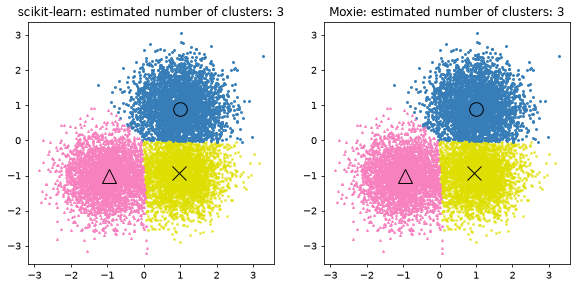

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
"estimate_bandwidth(quantile=0.2, n_samples=500)",PASS,(),(),4.44e-16,4.43e-16,"rtol=1e-12, atol=0",,same MT19937 subset; distance sums in a different order
estimate_bandwidth(small) default quantile,PASS,(),(),0,0,"rtol=1e-12, atol=0",,distance sums in a different order
cluster_centers_,PASS,"(3, 2)","(3, 2)",2.22e-16,2.49e-16,"rtol=1e-12, atol=1e-12",,neighborhood means are Float64 sums in a different order (neighbors engine vs sklearn's BallTree); a 1e-12 relative bound covers the summation-order roundoff
labels_,PASS,"(10000,)","(10000,)",,,exact,0 mismatches,
predict (200 new points),PASS,"(200,)","(200,)",,,exact,0 mismatches,
get_bin_seeds(min_bin_freq=5),PASS,"(34, 2)","(34, 2)",2.4e-07,7.98e-08,"rtol=1.2e-07, atol=0",,"sklearn's Float32 grid times a NumPy float64 bandwidth promotes to Float64; Moxie scales in Float32 (sklearn's result for a Python-float bin_size). Same bins, Float32 rounding only"
cluster_all=False labels_ (orphans = -1),PASS,"(400,)","(400,)",,,exact,0 mismatches,
cluster_all=False cluster_centers_,PASS,"(17, 2)","(17, 2)",4.44e-16,5.33e-16,"rtol=1e-12, atol=1e-12",,neighborhood means are Float64 sums in a different order (neighbors engine vs sklearn's BallTree); a 1e-12 relative bound covers the summation-order roundoff
mean_shift() centers,PASS,"(3, 2)","(3, 2)",4.44e-16,3.76e-16,"rtol=1e-12, atol=1e-12",,neighborhood means are Float64 sums in a different order (neighbors engine vs sklearn's BallTree); a 1e-12 relative bound covers the summation-order roundoff
mean_shift() labels,PASS,"(400,)","(400,)",,,exact,0 mismatches,


In [5]:
import matplotlib.pyplot as plt

mx = nb.results["mean_shift"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), dpi=70)
colors = ["#dede00", "#377eb8", "#f781bf"]
markers = ["x", "o", "^"]
for ax, lab, cc, title in ((axes[0], labels, cluster_centers, "scikit-learn"),
                           (axes[1], mx["labels"], mx["centers"], "Moxie")):
    for k, col in zip(range(len(cc)), colors):
        my_members = lab == k
        ax.plot(X[my_members, 0], X[my_members, 1], markers[k], color=col, markersize=2)
        ax.plot(cc[k][0], cc[k][1], markers[k], markerfacecolor=col, markeredgecolor="k", markersize=14)
    ax.set_title(f"{title}: estimated number of clusters: {len(cc)}")
plt.show()
moxie_nb.side_by_side(sklearn=cluster_centers, moxie=mx["centers"])

shift_reason = ("neighborhood means are Float64 sums in a different order (neighbors engine vs "
                "sklearn's BallTree); a 1e-12 relative bound covers the summation-order roundoff")
nb.compare("estimate_bandwidth(quantile=0.2, n_samples=500)", bandwidth, mx["floats"][0], rtol=1e-12,
           reason="same MT19937 subset; distance sums in a different order")
nb.compare("estimate_bandwidth(small) default quantile", sk_auto_bw, mx["floats"][1], rtol=1e-12,
           reason="distance sums in a different order")
nb.compare("cluster_centers_", cluster_centers, mx["centers"], rtol=1e-12, atol=1e-12, reason=shift_reason)
nb.compare("labels_", labels, mx["labels"], exact=True)
nb.compare("predict (200 new points)", sk_predict, mx["predict"], exact=True)
nb.compare("get_bin_seeds(min_bin_freq=5)", sk_bins, mx["bins"], rtol=1.2e-7,
           reason="sklearn's Float32 grid times a NumPy float64 bandwidth promotes to Float64; Moxie scales in "
                  "Float32 (sklearn's result for a Python-float bin_size). Same bins, Float32 rounding only")
nb.compare("cluster_all=False labels_ (orphans = -1)", sk_partial.labels_, mx["partial_labels"], exact=True)
nb.compare("cluster_all=False cluster_centers_", sk_partial.cluster_centers_, mx["partial_centers"],
           rtol=1e-12, atol=1e-12, reason=shift_reason)
nb.compare("mean_shift() centers", sk_fn_centers, mx["fn_centers"], rtol=1e-12, atol=1e-12, reason=shift_reason)
nb.compare("mean_shift() labels", sk_fn_labels, mx["fn_labels"], exact=True)
nb.compare("explicit seeds, max_iter=5 centers", sk_seeded.cluster_centers_, mx["seeded_centers"],
           rtol=1e-12, atol=1e-12, reason=shift_reason)
nb.compare("explicit seeds labels_", sk_seeded.labels_, mx["seeded_labels"], exact=True)
nb.compare("n_iter_ (example, cluster_all=False, seeded, clone)",
           [ms.n_iter_, sk_partial.n_iter_, sk_seeded.n_iter_, sk_clone.n_iter_], mx["n_iter"], exact=True)
nb.compare("Float32 labels_", sk_32.labels_, mx["f32_labels"], exact=True)
nb.compare("Float32 cluster_centers_", sk_32.cluster_centers_, mx["f32_centers"], rtol=1e-5, atol=1e-6,
           reason="Float32 neighborhood means; accumulation order differs (~10 ulp at these magnitudes)")
nb.compare("clone + set_params(bandwidth=0.6) refit labels_", sk_clone.labels_, mx["clone_labels"], exact=True)
nb.compare("clone + set_params refit centers", sk_clone.cluster_centers_, mx["clone_centers"],
           rtol=1e-12, atol=1e-12, reason=shift_reason)
nb.note("get_bin_seeds scaling dtype", "ADAPTED",
        "Moxie's bin_size is Float64 regardless of Python scalar type; seeds use sklearn's Python-float "
        "(Float32) scaling. Documented in algorithms/mean_shift/docs/api.md; centers and labels still match")
nb.report()
nb.assert_parity()